# 🚲 EDA — Estaciones Bicing Barcelona

**Fuentes de datos:**
- `station_information`: metadatos estáticos (nombre, coordenadas, capacidad)
- `station_status`: estado en tiempo real (bicicletas y docks disponibles)

**API base:** `https://api.bsmsa.eu/ext/api/bsm/gbfs/v2/en/`

---

## 0. Instalación y carga de librerías

In [8]:
# !pip install pandas numpy matplotlib seaborn plotly scipy

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
import warnings

warnings.filterwarnings('ignore')

# Estilo global matplotlib
sns.set_theme(style='whitegrid', font_scale=1.1)
PALETTE = {
    'Vacía':      '#d62728',
    'Casi vacía': '#ff7f0e',
    'Normal':     '#2ca02c',
    'Casi llena': '#1f77b4',
    'Llena':      '#9467bd',
}
CAT_ORDER = ['Vacía', 'Casi vacía', 'Normal', 'Casi llena', 'Llena']

print('✅ Librerías cargadas correctamente')

✅ Librerías cargadas correctamente


## 1. Ingesta de datos desde la API GBFS

In [9]:
df_info   = pd.read_csv('bicing_info.csv')
df_status = pd.read_csv(''
                        'bicing_estat.csv')

print(f'📁 bicing_info:  {df_info.shape[0]:,} filas x {df_info.shape[1]} columnas')
print(f'📁 bicing_estat: {df_status.shape[0]:,} filas x {df_status.shape[1]} columnas')

# Convertir timestamps Unix a datetime
df_status['last_reported'] = pd.to_datetime(df_status['last_reported'], unit='s', utc=True).dt.tz_convert('Europe/Madrid')

print(f'📅 Periodo estat:  {df_status["last_reported"].min()} → {df_status["last_reported"].max()}')

📁 bicing_info:  4,854,903 filas x 18 columnas
📁 bicing_estat: 4,358,950 filas x 14 columnas
📅 Periodo estat:  2026-01-31 23:29:06+01:00 → 2026-02-28 23:55:04+01:00


## 2. Preparación y join de los datasets

In [10]:
# --- Info estática: una fila por estación ---
df_info_clean = (
    df_info
    .assign(station_id=lambda d: d['station_id'].astype(str))
    [['station_id', 'name', 'lat', 'lon', 'altitude', 'capacity', 'post_code']]
    .drop_duplicates(subset='station_id', keep='first')
)

# --- Estado: snapshot más reciente por estación ---
df_status_clean = (
    df_status
    .assign(station_id=lambda d: d['station_id'].astype(str))
    .rename(columns={
        'num_bikes_available':                   'n_bikes',
        'num_bikes_available_types.mechanical':   'n_mechanical',
        'num_bikes_available_types.ebike':        'n_ebike',
        'num_docks_available':                    'n_docks',
    })
    .assign(
        is_installed = lambda d: d['is_installed'].astype(bool),
        is_renting   = lambda d: d['is_renting'].astype(bool),
        is_returning = lambda d: d['is_returning'].astype(bool),
    )
    .sort_values('last_reported', ascending=False)
    .drop_duplicates(subset='station_id', keep='first')   # snapshot más reciente
)

# --- Join ---
bicing = df_info_clean.merge(df_status_clean, on='station_id', how='inner')

# --- Variables derivadas ---
bicing['pct_bikes'] = bicing['n_bikes'] / bicing['capacity']
bicing['pct_docks'] = bicing['n_docks'] / bicing['capacity']
bicing['pct_ebike'] = np.where(bicing['n_bikes'] > 0, bicing['n_ebike'] / bicing['n_bikes'], np.nan)
bicing['station_active'] = bicing['is_installed'] & bicing['is_renting'] & bicing['is_returning']

def categorize_ocupacion(pct):
    if pct == 0:       return 'Vacía'
    elif pct < 0.25:   return 'Casi vacía'
    elif pct < 0.75:   return 'Normal'
    elif pct < 1.0:    return 'Casi llena'
    else:              return 'Llena'

bicing['ocupacion_cat'] = pd.Categorical(
    bicing['pct_bikes'].apply(categorize_ocupacion),
    categories=CAT_ORDER, ordered=True
)

print(f'✅ Dataset final: {bicing.shape[0]} estaciones x {bicing.shape[1]} variables')
bicing.info()

✅ Dataset final: 544 estaciones x 25 variables
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 544 entries, 0 to 543
Data columns (total 25 columns):
 #   Column               Non-Null Count  Dtype                        
---  ------               --------------  -----                        
 0   station_id           544 non-null    object                       
 1   name                 544 non-null    object                       
 2   lat                  544 non-null    float64                      
 3   lon                  544 non-null    float64                      
 4   altitude             523 non-null    float64                      
 5   capacity             544 non-null    int64                        
 6   post_code            541 non-null    float64                      
 7   n_bikes              544 non-null    int64                        
 8   is_charging_station  544 non-null    bool                         
 9   status               544 non-null    object        

## 3. Resumen estadístico (`describe`)

In [11]:
cols_num = ['capacity', 'n_bikes', 'n_mechanical', 'n_ebike', 'n_docks',
            'pct_bikes', 'pct_docks', 'altitude']

bicing[cols_num].describe().round(3)

,capacity,n_bikes,n_mechanical,n_ebike,n_docks,pct_bikes,pct_docks,altitude
count,544.000,544.000,544.000,544.000,544.000,544.000,544.000,523.000
mean,27.244,8.961,4.807,4.154,15.965,0.331,0.581,37.294
std,6.763,8.452,6.495,4.811,9.392,0.300,0.303,34.779
min,12.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,24.000,2.000,0.000,1.000,9.000,0.074,0.341,9.000
50%,27.000,6.000,1.000,2.000,17.000,0.235,0.667,26.000
75%,30.000,15.000,8.000,6.000,23.000,0.533,0.833,55.500
max,54.000,50.000,31.000,36.000,50.000,1.476,1.053,184.000


In [12]:
# Estaciones inactivas
(
    bicing
    .groupby(['is_installed', 'is_renting', 'is_returning'], dropna=False)
    .size()
    .reset_index(name='n')
    .sort_values('n', ascending=False)
)

,is_installed,is_renting,is_returning,n
1,True,True,True,543
0,True,False,False,1


## 4. Distribución de ocupación

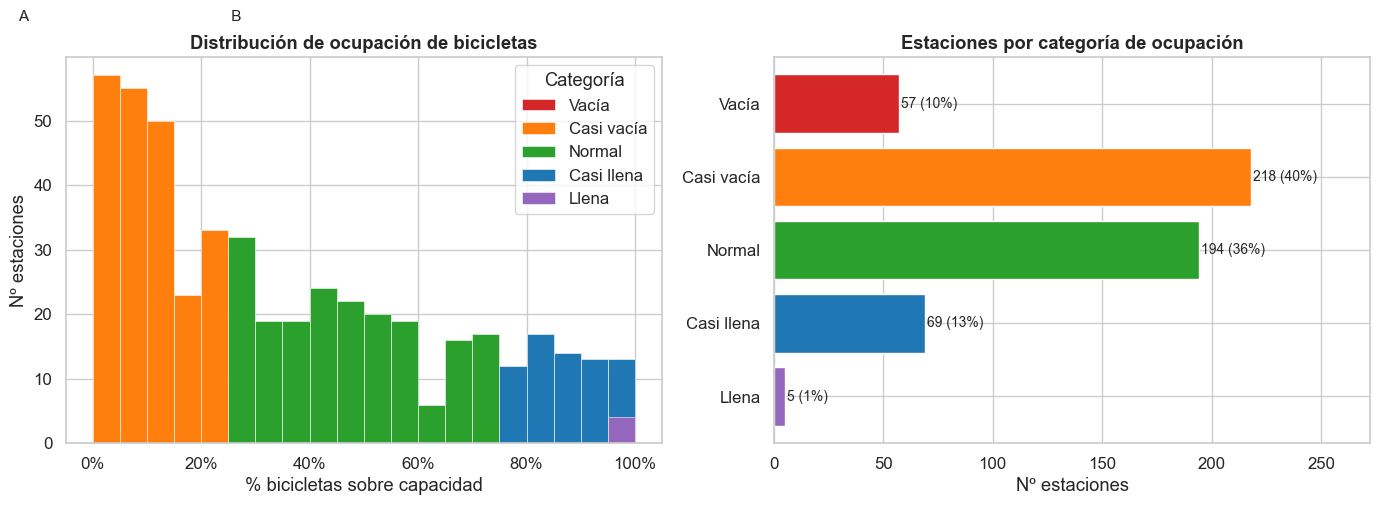

In [13]:
activas = bicing[bicing['station_active']].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A) Histograma continuo de pct_bikes
ax = axes[0]
bins = np.arange(0, 1.05, 0.05)
for cat in CAT_ORDER:
    subset = activas[activas['ocupacion_cat'] == cat]['pct_bikes']
    ax.hist(subset, bins=bins, color=PALETTE[cat], label=cat, edgecolor='white', linewidth=0.4)

ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title('Distribución de ocupación de bicicletas', fontweight='bold')
ax.set_xlabel('% bicicletas sobre capacidad')
ax.set_ylabel('Nº estaciones')
ax.legend(title='Categoría', loc='upper right')

# B) Barras por categoría
ax = axes[1]
counts = activas['ocupacion_cat'].value_counts().reindex(CAT_ORDER)
pcts   = counts / counts.sum()
bars = ax.barh(CAT_ORDER[::-1], counts.reindex(CAT_ORDER[::-1]),
               color=[PALETTE[c] for c in CAT_ORDER[::-1]])
for bar, n, p in zip(bars, counts.reindex(CAT_ORDER[::-1]), pcts.reindex(CAT_ORDER[::-1])):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height()/2,
            f'{n} ({p:.0%})', va='center', fontsize=10)
ax.set_title('Estaciones por categoría de ocupación', fontweight='bold')
ax.set_xlabel('Nº estaciones')
ax.set_xlim(0, counts.max() * 1.25)

plt.tight_layout()
plt.suptitle('A                                                B', y=1.01, x=0.02, ha='left', fontsize=11)
plt.show()

## 5. Bicicletas mecánicas vs eléctricas

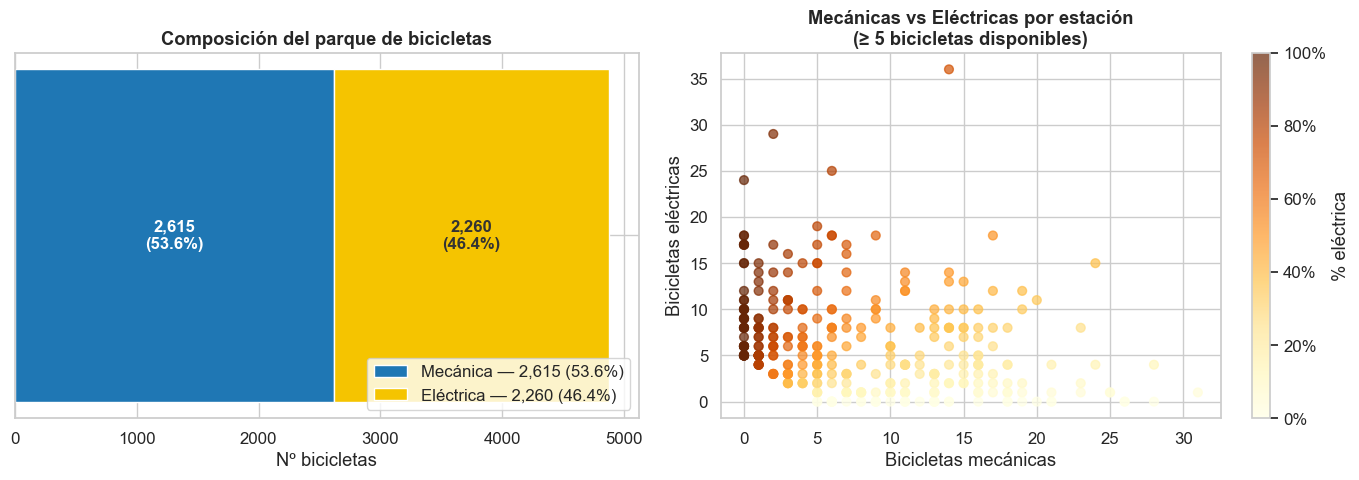

In [14]:
# A) Composición global (barras apiladas horizontales)
activas_bikes = activas[activas['n_bikes'] > 0]
total_mec  = activas_bikes['n_mechanical'].sum()
total_ebike = activas_bikes['n_ebike'].sum()
total = total_mec + total_ebike

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ax = axes[0]
ax.barh([''], [total_mec], color='#1f77b4', label=f'Mecánica — {total_mec:,} ({total_mec/total:.1%})')
ax.barh([''], [total_ebike], left=[total_mec], color='#f5c400',
        label=f'Eléctrica — {total_ebike:,} ({total_ebike/total:.1%})')
ax.set_title('Composición del parque de bicicletas', fontweight='bold')
ax.set_xlabel('Nº bicicletas')
ax.legend(loc='lower right')
ax.set_xlim(0, total * 1.05)
ax.annotate(f'{total_mec:,}\n({total_mec/total:.1%})', xy=(total_mec/2, 0),
            ha='center', va='center', color='white', fontweight='bold', fontsize=12)
ax.annotate(f'{total_ebike:,}\n({total_ebike/total:.1%})', xy=(total_mec + total_ebike/2, 0),
            ha='center', va='center', color='#333333', fontweight='bold', fontsize=12)

# B) Scatter mecánicas vs eléctricas por estación
ax = axes[1]
scat = activas_bikes[activas_bikes['n_bikes'] >= 5]
sc = ax.scatter(scat['n_mechanical'], scat['n_ebike'],
                c=scat['pct_ebike'], cmap='YlOrBr', alpha=0.7, s=40)
plt.colorbar(sc, ax=ax, label='% eléctrica', format=mticker.PercentFormatter(xmax=1))
ax.set_title('Mecánicas vs Eléctricas por estación\n(≥ 5 bicicletas disponibles)', fontweight='bold')
ax.set_xlabel('Bicicletas mecánicas')
ax.set_ylabel('Bicicletas eléctricas')

plt.tight_layout()
plt.show()

## 6. Capacidad y altitud

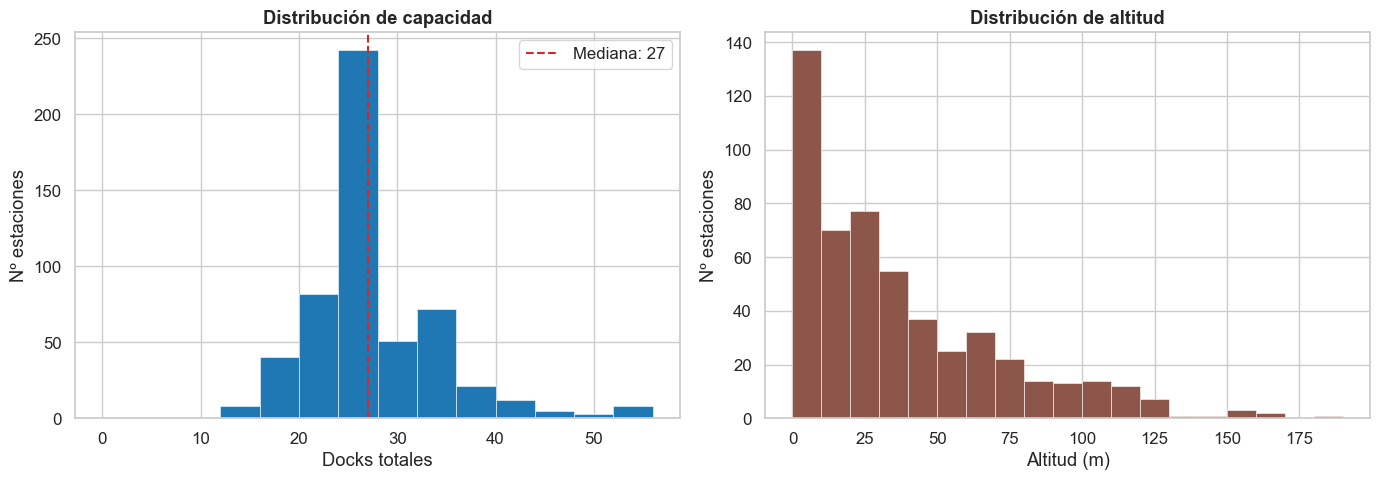

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# A) Distribución de capacidad
ax = axes[0]
med_cap = bicing['capacity'].median()
ax.hist(bicing['capacity'].dropna(), bins=range(0, int(bicing['capacity'].max()) + 5, 4),
        color='#1f77b4', edgecolor='white', linewidth=0.4)
ax.axvline(med_cap, color='#d62728', linestyle='--', linewidth=1.5, label=f'Mediana: {med_cap:.0f}')
ax.legend()
ax.set_title('Distribución de capacidad', fontweight='bold')
ax.set_xlabel('Docks totales')
ax.set_ylabel('Nº estaciones')

# B) Distribución de altitud
ax = axes[1]
alt = bicing[bicing['altitude'].notna() & (bicing['altitude'] >= 0)]['altitude']
ax.hist(alt, bins=range(0, int(alt.max()) + 10, 10), color='#8c564b', edgecolor='white', linewidth=0.4)
ax.set_title('Distribución de altitud', fontweight='bold')
ax.set_xlabel('Altitud (m)')
ax.set_ylabel('Nº estaciones')

plt.tight_layout()
plt.show()

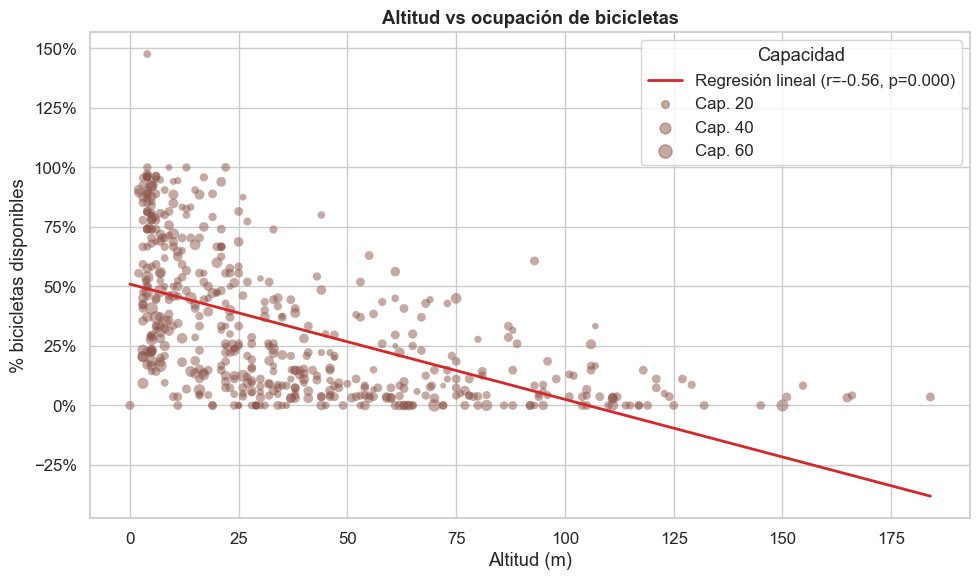

r de Pearson: -0.563  |  p-value: 0.0000


In [16]:
# ¿Las estaciones de mayor altitud tienen menos bicicletas? (efecto gravitacional)
subset_alt = activas[activas['altitude'].notna() & (activas['altitude'] >= 0)].copy()

slope, intercept, r, p, _ = stats.linregress(subset_alt['altitude'], subset_alt['pct_bikes'])

fig, ax = plt.subplots(figsize=(10, 6))
sc = ax.scatter(subset_alt['altitude'], subset_alt['pct_bikes'],
                s=subset_alt['capacity'] * 1.5, alpha=0.5, color='#8c564b', edgecolors='none')

x_line = np.linspace(subset_alt['altitude'].min(), subset_alt['altitude'].max(), 200)
ax.plot(x_line, slope * x_line + intercept, color='#d62728', linewidth=2,
        label=f'Regresión lineal (r={r:.2f}, p={p:.3f})')

ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title('Altitud vs ocupación de bicicletas', fontweight='bold')
ax.set_subtitle = ax.set_title
ax.set_xlabel('Altitud (m)')
ax.set_ylabel('% bicicletas disponibles')
ax.legend()

# Leyenda de tamaño
for sz in [20, 40, 60]:
    ax.scatter([], [], s=sz*1.5, c='#8c564b', alpha=0.5, label=f'Cap. {sz}')
ax.legend(title='Capacidad', loc='upper right')

plt.tight_layout()
plt.show()
print(f'r de Pearson: {r:.3f}  |  p-value: {p:.4f}')

## 7. Top estaciones: más llenas y más vacías

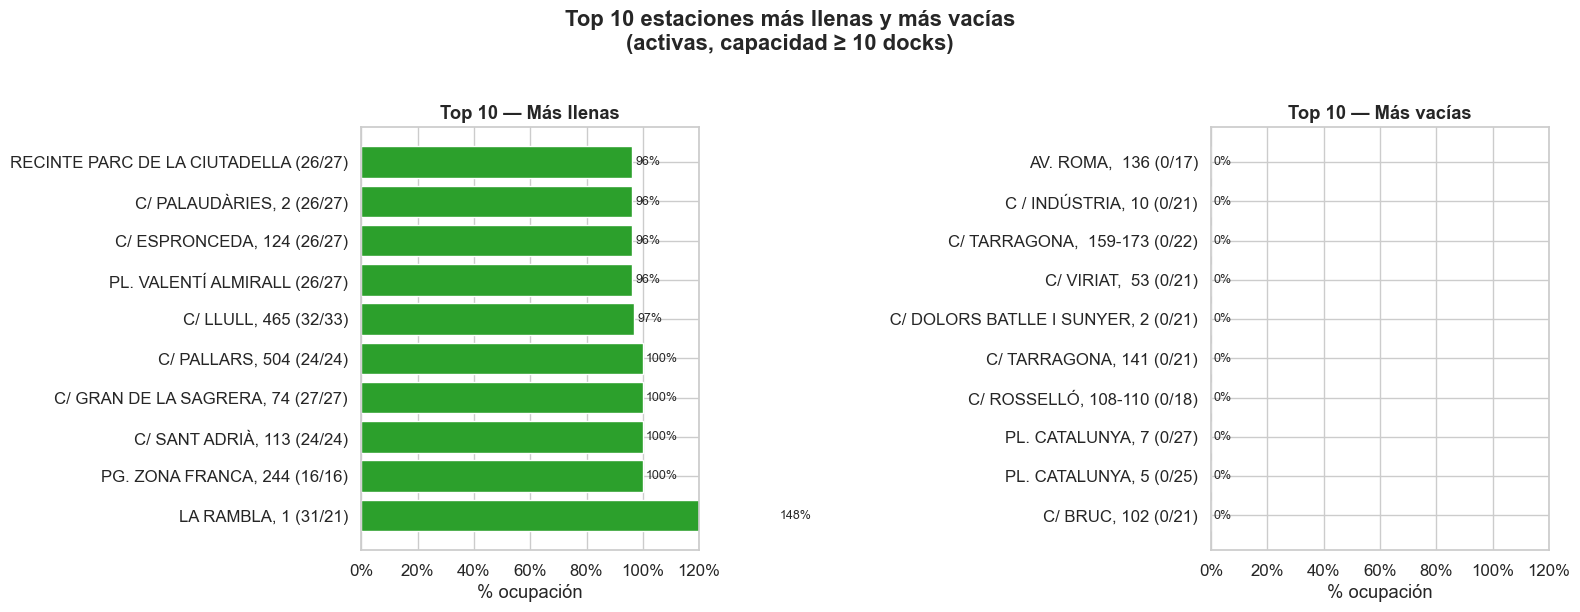

In [17]:
eligible = activas[activas['capacity'] >= 10].copy()
top_llenas = eligible.nlargest(10, 'pct_bikes').assign(tipo='Más llenas')
top_vacias = eligible.nsmallest(10, 'pct_bikes').assign(tipo='Más vacías')
top = pd.concat([top_llenas, top_vacias])
top['label'] = top['name'] + ' (' + top['n_bikes'].astype(str) + '/' + top['capacity'].astype(str) + ')'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

for ax, (tipo, color) in zip(axes, [('Más llenas', '#2ca02c'), ('Más vacías', '#d62728')]):
    df_t = top[top['tipo'] == tipo].sort_values('pct_bikes', ascending=(tipo == 'Más vacías'))
    bars = ax.barh(df_t['label'], df_t['pct_bikes'], color=color)
    for bar, val in zip(bars, df_t['pct_bikes']):
        ax.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{val:.0%}', va='center', fontsize=9)
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    ax.set_xlim(0, 1.2)
    ax.set_title(f'Top 10 — {tipo}', fontweight='bold')
    ax.set_xlabel('% ocupación')

plt.suptitle('Top 10 estaciones más llenas y más vacías\n(activas, capacidad ≥ 10 docks)',
             fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

## 8. Correlaciones entre variables numéricas

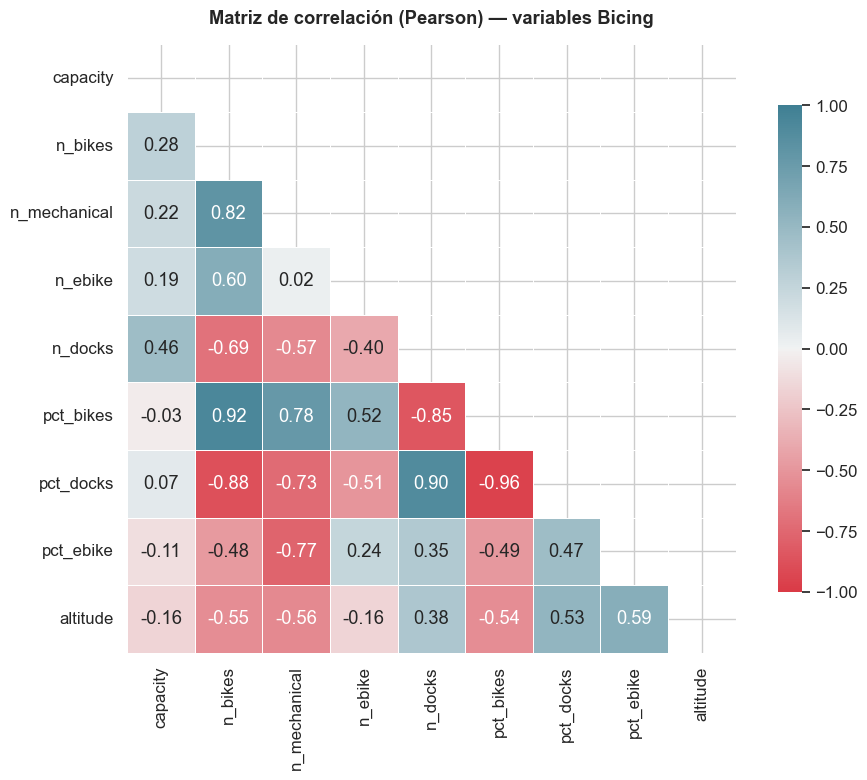

In [18]:
vars_num = ['capacity', 'n_bikes', 'n_mechanical', 'n_ebike', 'n_docks',
            'pct_bikes', 'pct_docks', 'pct_ebike', 'altitude']

corr = activas[vars_num].dropna().corr(method='pearson')

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))   # solo triángulo superior
cmap = sns.diverging_palette(10, 220, as_cmap=True)

sns.heatmap(
    corr, mask=mask, annot=True, fmt='.2f', cmap=cmap,
    vmin=-1, vmax=1, center=0, linewidths=0.5,
    square=True, ax=ax, cbar_kws={'shrink': 0.8}
)
ax.set_title('Matriz de correlación (Pearson) — variables Bicing', fontweight='bold', pad=15)
plt.tight_layout()
plt.show()

## 9. Análisis por código postal
> **Análisis extra** respecto al EDA original en R

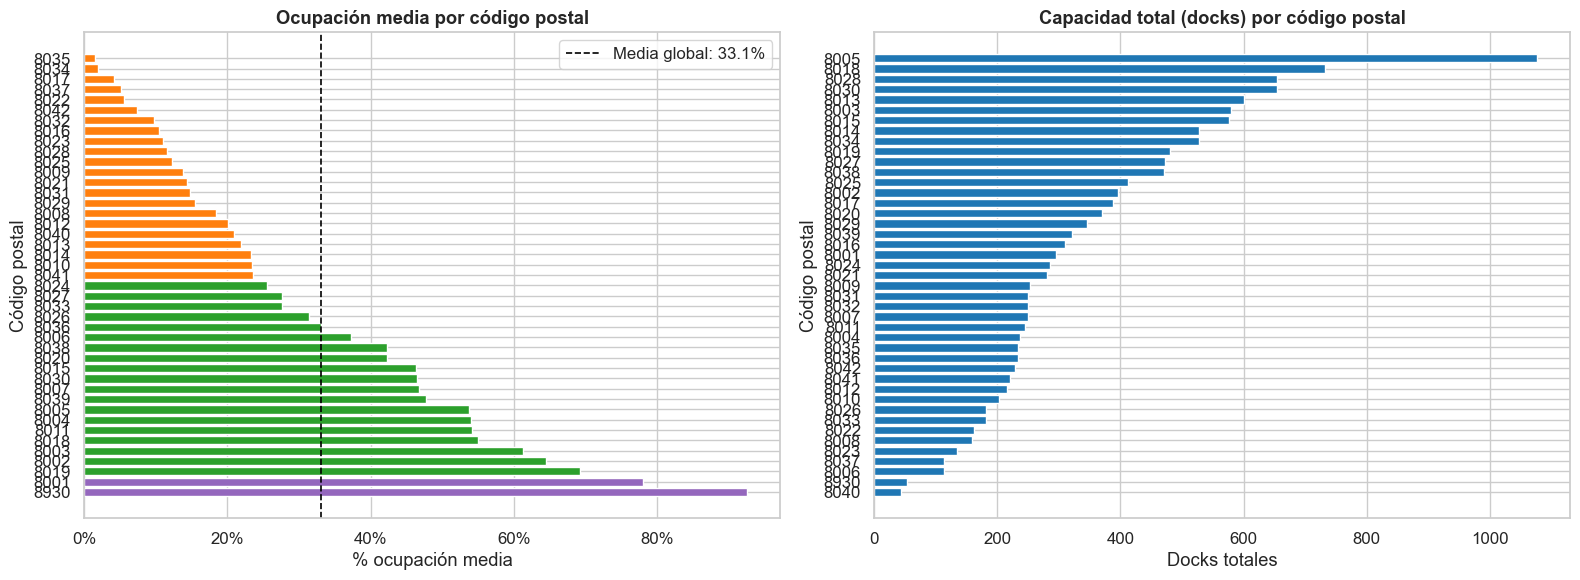

post_code  n_estaciones  capacidad_total  pct_bikes_media  pct_ebike_media  n_bikes_total
     8930             1               54         0.925926         0.720000             50
     8001            12              295         0.780044         0.292249            233
     8019            17              480         0.692607         0.332847            329
     8002            16              396         0.645582         0.256700            251
     8003            22              579         0.612555         0.165379            342
     8018            26              732         0.549924         0.374883            389
     8011             9              245         0.542145         0.583351            142
     8004            10              237         0.539603         0.607724            126
     8005            34             1077         0.537989         0.277167            552
     8039             9              322         0.477484         0.395949            147
     8007 

In [19]:
by_cp = (
    activas.dropna(subset=['post_code'])
    .assign(post_code=lambda d: d['post_code'].astype(int).astype(str))
    .groupby('post_code')
    .agg(
        n_estaciones   = ('station_id', 'count'),
        capacidad_total= ('capacity',   'sum'),
        pct_bikes_media= ('pct_bikes',  'mean'),
        pct_ebike_media = ('pct_ebike', 'mean'),
        n_bikes_total  = ('n_bikes',    'sum'),
    )
    .sort_values('pct_bikes_media', ascending=False)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Ocupación media por CP
ax = axes[0]
colors = [PALETTE['Llena'] if v > 0.75 else
          PALETTE['Normal'] if v > 0.25 else
          PALETTE['Casi vacía'] for v in by_cp['pct_bikes_media']]
ax.barh(by_cp['post_code'], by_cp['pct_bikes_media'], color=colors)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_title('Ocupación media por código postal', fontweight='bold')
ax.set_xlabel('% ocupación media')
ax.set_ylabel('Código postal')
ax.axvline(activas['pct_bikes'].mean(), color='black', linestyle='--',
           linewidth=1.2, label=f'Media global: {activas["pct_bikes"].mean():.1%}')
ax.legend()

# Capacidad total por CP
ax = axes[1]
ax.barh(by_cp.sort_values('capacidad_total')['post_code'],
        by_cp.sort_values('capacidad_total')['capacidad_total'],
        color='#1f77b4')
ax.set_title('Capacidad total (docks) por código postal', fontweight='bold')
ax.set_xlabel('Docks totales')
ax.set_ylabel('Código postal')

plt.tight_layout()
plt.show()
print(by_cp.to_string(index=False))

## 10. Análisis extra — Distribución temporal de reportes
> **Análisis extra:** como el CSV cubre todo febrero 2026, podemos analizar la frecuencia de actualizaciones por estación y detectar estaciones con cobertura deficiente.

In [20]:
# Reconvertir timestamps para el df_status completo
df_status_ts = df_status.copy()
if not pd.api.types.is_datetime64_any_dtype(df_status_ts['last_reported']):
    df_status_ts['last_reported'] = pd.to_datetime(df_status_ts['last_reported'], unit='s', utc=True).dt.tz_convert('Europe/Madrid')

df_status_ts['date'] = df_status_ts['last_reported'].dt.date
df_status_ts['hour'] = df_status_ts['last_reported'].dt.hour

# Registros por día
by_day = df_status_ts.groupby('date').size().reset_index(name='n_registros')

# Ocupación media horaria (promedio de todas las estaciones por hora del día)
by_hour = (
    df_status_ts
    .rename(columns={'num_bikes_available': 'n_bikes'})
    .merge(df_info_clean[['station_id', 'capacity']].assign(station_id=lambda d: d['station_id'].astype(str)),
           left_on='station_id', right_on='station_id')
    .assign(pct_bikes=lambda d: d['n_bikes'] / d['capacity'])
    .groupby('hour')
    .agg(pct_bikes_mean=('pct_bikes', 'mean'), n=('pct_bikes', 'count'))
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Registros por día
ax = axes[0]
ax.bar(range(len(by_day)), by_day['n_registros'], color='#1f77b4', width=0.8)
ax.set_xticks(range(len(by_day)))
ax.set_xticklabels([str(d) for d in by_day['date']], rotation=45, ha='right', fontsize=8)
ax.set_title('Registros de estado por día (febrero 2026)', fontweight='bold')
ax.set_ylabel('Nº registros')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1000:.0f}k'))

# Ocupación media por hora del día
ax = axes[1]
ax.plot(by_hour['hour'], by_hour['pct_bikes_mean'], marker='o', color='#2ca02c', linewidth=2)
ax.fill_between(by_hour['hour'], by_hour['pct_bikes_mean'], alpha=0.15, color='#2ca02c')
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xticks(range(0, 24))
ax.set_title('Ocupación media por hora del día\n(todas las estaciones, todo febrero)', fontweight='bold')
ax.set_xlabel('Hora del día')
ax.set_ylabel('% ocupación media')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

ValueError: You are trying to merge on int64 and object columns for key 'station_id'. If you wish to proceed you should use pd.concat

## 11. Análisis extra — Estaciones outliers: alta capacidad, baja ocupación
> Identifica estaciones grandes que sistemáticamente tienen pocas bicis disponibles — candidatas a rebalanceo.

In [ ]:
# Cuadrantes de capacidad vs ocupación
med_cap  = activas['capacity'].median()
med_pct  = activas['pct_bikes'].median()

def quadrant(row):
    if row['capacity'] >= med_cap and row['pct_bikes'] < med_pct:  return 'Alta cap. / Baja ocup. ⚠️'
    if row['capacity'] >= med_cap and row['pct_bikes'] >= med_pct: return 'Alta cap. / Alta ocup. ✅'
    if row['capacity'] < med_cap  and row['pct_bikes'] < med_pct:  return 'Baja cap. / Baja ocup.'
    return 'Baja cap. / Alta ocup.'

activas = activas.copy()
activas['quadrant'] = activas.apply(quadrant, axis=1)

quad_colors = {
    'Alta cap. / Baja ocup. ⚠️': '#d62728',
    'Alta cap. / Alta ocup. ✅': '#2ca02c',
    'Baja cap. / Baja ocup.':    '#ff7f0e',
    'Baja cap. / Alta ocup.':    '#1f77b4',
}

fig, ax = plt.subplots(figsize=(11, 8))
for quad, grp in activas.groupby('quadrant'):
    ax.scatter(grp['capacity'], grp['pct_bikes'],
               alpha=0.65, s=50, color=quad_colors[quad], label=quad)

ax.axvline(med_cap, color='grey', linestyle='--', linewidth=1)
ax.axhline(med_pct, color='grey', linestyle='--', linewidth=1)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
ax.set_xlabel('Capacidad (docks)')
ax.set_ylabel('% ocupación')
ax.set_title('Capacidad vs Ocupación — cuadrantes operativos', fontweight='bold')
ax.legend(title='Cuadrante', loc='upper right')
ax.text(med_cap + 0.5, ax.get_ylim()[1]*0.97, f'Mediana cap={med_cap:.0f}',
        color='grey', fontsize=8)
ax.text(ax.get_xlim()[0]+0.5, med_pct + 0.01, f'Mediana ocup={med_pct:.1%}',
        color='grey', fontsize=8)

plt.tight_layout()
plt.show()

# Top candidatas a rebalanceo
print('\n🔴 Top 10 estaciones candidatas a rebalanceo (alta capacidad, baja ocupación):')
(
    activas[activas['quadrant'] == 'Alta cap. / Baja ocup. ⚠️']
    .nlargest(10, 'capacity')[['name', 'capacity', 'n_bikes', 'pct_bikes', 'post_code']]
    .assign(pct_bikes=lambda d: d['pct_bikes'].map('{:.1%}'.format))
    .to_string(index=False)
)

## 12. Mapa interactivo de estaciones (Plotly)

In [ ]:
map_df = activas[activas['lat'].notna() & activas['lon'].notna()].copy()
map_df['ocupacion_cat_str'] = map_df['ocupacion_cat'].astype(str)
map_df['hover'] = (
    '<b>' + map_df['name'] + '</b><br>' +
    '🚲 Bikes: ' + map_df['n_bikes'].astype(str) + ' / ' + map_df['capacity'].astype(str) + '<br>' +
    '⚡ Eléctricas: ' + map_df['n_ebike'].astype(str) + '<br>' +
    '🔧 Mecánicas: ' + map_df['n_mechanical'].astype(str) + '<br>' +
    '🅿️ Docks libres: ' + map_df['n_docks'].astype(str) + '<br>' +
    '📊 Ocupación: ' + (map_df['pct_bikes'] * 100).round(0).astype(int).astype(str) + '%'
)

fig = px.scatter_mapbox(
    map_df,
    lat='lat', lon='lon',
    color='ocupacion_cat_str',
    color_discrete_map=PALETTE,
    category_orders={'ocupacion_cat_str': CAT_ORDER},
    size='capacity',
    size_max=18,
    hover_name='name',
    custom_data=['hover'],
    mapbox_style='open-street-map',
    center={'lat': 41.3851, 'lon': 2.1734},
    zoom=12,
    title='Estaciones Bicing Barcelona — ocupación actual',
    labels={'ocupacion_cat_str': 'Ocupación'},
    height=600,
)
fig.update_traces(hovertemplate='%{customdata[0]}<extra></extra>')
fig.update_layout(margin={'r': 0, 't': 40, 'l': 0, 'b': 0})
fig.show()

## 13. Resumen ejecutivo

In [ ]:
ts_snapshot = bicing['last_reported'].max()
act = bicing[bicing['station_active']]

total_bikes = act['n_bikes'].sum()
total_mec   = act['n_mechanical'].sum()
total_eb    = act['n_ebike'].sum()
total_docks = act['n_docks'].sum()
cap_total   = act['capacity'].sum()
pct_ocup    = total_bikes / cap_total
pct_elec    = total_eb / total_bikes
n_vacias    = (act['n_bikes'] == 0).sum()
n_llenas    = (act['n_docks'] == 0).sum()

print('=' * 47)
print('    RESUMEN EJECUTIVO — BICING BARCELONA')
print('=' * 47)
print(f'Timestamp snapshot:      {ts_snapshot}')
print()
print(f'Estaciones activas:      {len(act)}')
print(f'Capacidad total:         {cap_total:,} docks')
print(f'Bicicletas disponibles:  {total_bikes:,}')
print(f'  → Mecánicas:           {total_mec:,} ({total_mec/total_bikes:.1%})')
print(f'  → Eléctricas:          {total_eb:,} ({pct_elec:.1%})')
print(f'Docks libres:            {total_docks:,}')
print(f'Ocupación global:        {pct_ocup:.1%}')
print(f'Estaciones completamente vacías:  {n_vacias}')
print(f'Estaciones completamente llenas:  {n_llenas}')
print('=' * 47)